# 02 — Um exemplo pequeno para entender Dijkstra

**Pergunta:** saindo do ponto E, qual atendimento podemos alcançar pelo menor caminho?

Este exemplo é inventado apenas para aprender. Não é um mapa de Fortaleza. Há seis cruzamentos (A–F), dois atendimentos (A e F) e comprimentos em metros.

- Um **nó** é um ponto da rede: aqui, um cruzamento.
- Uma **aresta** é uma ligação entre dois pontos: aqui, um trecho de rua.
- O **peso** é o comprimento do trecho.
- A rua B → E é de mão única. Não existe E → B.

Para simplificar o exemplo, os atendimentos e a origem já estão nos nós. No caso real, precisamos acrescentar também as pequenas ligações entre os pontos e a rede.


In [1]:
from pathlib import Path
import heapq
import sys

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"PLANO.md").exists())
sys.path.insert(0,str(RAIZ/"scripts"))
import estilo
estilo.aplicar()
SAIDA = RAIZ/"dados/processados/retomada/exemplo"
FIG = RAIZ/"figuras/retomada/exemplo"
SAIDA.mkdir(parents=True,exist_ok=True)
FIG.mkdir(parents=True,exist_ok=True)


## 1. Escrever as ruas como dados

A tabela diz de onde podemos sair, onde podemos chegar e qual o comprimento. Uma rua de dois sentidos vira duas ligações no grafo; a rua de mão única vira somente uma.


In [2]:
ruas = pd.DataFrame([
    ("A","B",100,True),("B","C",100,True),
    ("A","D",120,True),("D","E",140,True),
    ("E","F",180,True),("C","F",120,True),
    ("B","E",60,False),
],columns=["de","para","comprimento_m","dois_sentidos"])
G = nx.DiGraph()
for r in ruas.itertuples():
    G.add_edge(r.de,r.para,length=r.comprimento_m)
    if r.dois_sentidos:
        G.add_edge(r.para,r.de,length=r.comprimento_m)
pos = {"A":(0,1),"B":(1,1),"C":(2,1),"D":(0,0),"E":(1,0),"F":(2,0)}
atendimentos = ["A","F"]
display(ruas)
assert G.has_edge("B","E") and not G.has_edge("E","B")


,de,para,comprimento_m,dois_sentidos
0,A,B,100,True
1,B,C,100,True
2,A,D,120,True
3,D,E,140,True
4,E,F,180,True
5,C,F,120,True
6,B,E,60,False


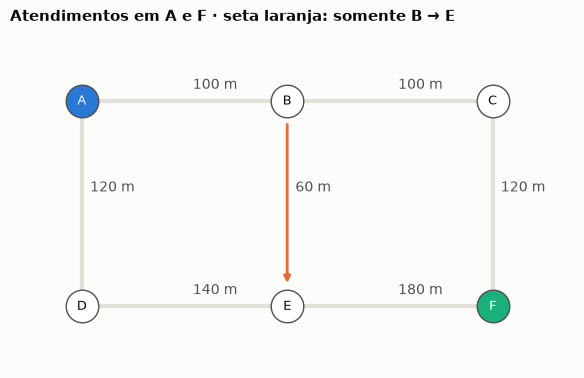

In [3]:
fig,ax = plt.subplots(figsize=(8,4.4))
for r in ruas.itertuples():
    x0,y0 = pos[r.de]; x1,y1 = pos[r.para]
    if r.dois_sentidos:
        ax.plot([x0,x1],[y0,y1],color=estilo.GRADE,linewidth=3,zorder=1)
    else:
        ax.annotate("",xy=(x1,y1+.1),xytext=(x0,y0-.1),
                    arrowprops={"arrowstyle":"-|>","color":estilo.LARANJA,"lw":2},zorder=2)
    ax.text((x0+x1)/2+.04,(y0+y1)/2+.06,f"{r.comprimento_m} m",fontsize=10,color=estilo.TEXTO_2)
for n,(x,y) in pos.items():
    cor = estilo.AZUL if n=="A" else estilo.VERDE_AGUA if n=="F" else "white"
    ax.scatter(x,y,s=550,facecolor=cor,edgecolor=estilo.TEXTO_2,zorder=3)
    ax.text(x,y,n,ha="center",va="center",color="white" if n in atendimentos else estilo.TEXTO,zorder=4)
ax.set_aspect("equal")
ax.set_xlim(-.35,2.4);ax.set_ylim(-.3,1.35);ax.set_axis_off()
ax.set_title("Atendimentos em A e F · seta laranja: somente B → E")
fig.savefig(FIG/"01_ruas_do_exemplo.png")
fig.savefig(FIG/"01_ruas_do_exemplo.pdf")
plt.show()


## 2. Conferir os caminhos com as próprias ruas

Saindo de E:

- E → F tem **180 m**.
- E → D → A tem **140 + 120 = 260 m**.
- E → B → A não é permitido: a seta só permite **B → E**.

Portanto, para a origem E, o atendimento F está mais perto pela rua, mesmo que o caminho proibido até A pareça curto no desenho. Não há velocidade ou tempo nesta conta.


In [4]:
caminhos = []
for destino in atendimentos:
    caminho = nx.shortest_path(G,"E",destino,weight="length")
    distancia = nx.shortest_path_length(G,"E",destino,weight="length")
    caminhos.append({"origem":"E","atendimento":destino,"caminho":" → ".join(caminho),"distancia_m":distancia})
display(pd.DataFrame(caminhos))
assert nx.shortest_path_length(G,"E","F",weight="length")==180
assert nx.shortest_path_length(G,"E","A",weight="length")==260


,origem,atendimento,caminho,distancia_m
0,E,A,E → D → A,260
1,E,F,E → F,180


## 3. Acompanhar as atualizações do algoritmo

Dijkstra começa com distância zero na origem e infinito nos outros nós. A cada passo:

1. Escolhe o nó ainda não fechado com menor distância conhecida.
2. Examina as saídas permitidas desse nó.
3. Atualiza um vizinho quando encontrou um caminho menor.

Os comprimentos são não negativos. Por isso é possível fechar os nós nessa ordem. A tabela registra o que foi mudado em cada passo, em vez de mostrar só a resposta pronta.


In [5]:
dist = {no:np.inf for no in G.nodes}
dist["E"] = 0
fila = [(0,"E")]
fechados = set()
passos = []
while fila:
    distancia,no = heapq.heappop(fila)
    if no in fechados:
        continue
    fechados.add(no)
    atualizacoes = []
    for vizinho,aresta in G[no].items():
        candidata = distancia+aresta["length"]
        if candidata < dist[vizinho]:
            dist[vizinho] = candidata
            heapq.heappush(fila,(candidata,vizinho))
            atualizacoes.append(f"{vizinho}: {candidata} m")
    passos.append({"passo":len(passos)+1,"no_fechado":no,
                   "distancia_m":distancia,"melhorias":", ".join(atualizacoes) or "nenhuma"})
passos = pd.DataFrame(passos)
display(passos)
passos.to_csv(SAIDA/"passos_a_partir_de_E.csv",index=False)
for no in G.nodes:
    assert dist[no]==nx.shortest_path_length(G,"E",no,weight="length")


,passo,no_fechado,distancia_m,melhorias
0,1,E,0,"D: 140 m, F: 180 m"
1,2,D,140,A: 260 m
2,3,F,180,C: 300 m
3,4,A,260,B: 360 m
4,5,C,300,nenhuma
5,6,B,360,nenhuma


## 4. Calcular todos os pontos de uma vez

Na pesquisa, queremos a distância **de cada setor até um atendimento**. Uma maneira eficiente é partir dos dois atendimentos ao mesmo tempo, no **grafo invertido**.

Inverter aqui significa trocar a direção de cada ligação. Isso permite começar nos atendimentos e obter as distâncias que, na rede original, eram percorridas na direção até eles.

**Não invertemos as mãos das ruas da cidade real.** Invertemos somente a representação usada pelo cálculo. Ao interpretar o caminho, ele continua indo da origem para o atendimento na rede original.


In [6]:
nos = sorted(G.nodes)
indice = {no:i for i,no in enumerate(nos)}
# Cada ligação original u → v é escrita como v → u para o cálculo.
matriz_invertida = coo_matrix((
    [d["length"] for u,v,d in G.edges(data=True)],
    ([indice[v] for u,v in G.edges],[indice[u] for u,v in G.edges])
),shape=(len(nos),len(nos))).tocsr()
dist_ate,_,origem = dijkstra(
    matriz_invertida,directed=True,indices=[indice[p] for p in atendimentos],
    min_only=True,return_predecessors=True
)
resultado = pd.DataFrame({
    "no":nos,"atendimento_mais_proximo":[nos[o] for o in origem],
    "distancia_m":dist_ate
})
for r in resultado.itertuples():
    alternativas = [nx.shortest_path_length(G,r.no,p,weight="length") for p in atendimentos]
    assert r.distancia_m==min(alternativas)
display(resultado)
resultado.to_csv(SAIDA/"distancias_ate_atendimentos.csv",index=False)


,no,atendimento_mais_proximo,distancia_m
0,A,A,0.0
1,B,A,100.0
2,C,F,120.0
3,D,A,120.0
4,E,F,180.0
5,F,F,0.0


## 5. Ver por que usar a direção errada muda a resposta

Se partirmos dos atendimentos usando a rede original, calculamos o trajeto **do atendimento até o ponto**, que pode ter comprimento diferente.

Nesse cálculo errado para nossa pergunta, A → B → E tem 160 m. Isso faria E ser atribuído a A. Mas E não pode voltar por esse caminho: seu atendimento mais próximo é F, a 180 m.

Esta comparação é uma verificação do sentido do trajeto, não uma comparação de redes de carro e pedestres.


In [7]:
matriz_original = matriz_invertida.T.tocsr()
dist_errada,_,origem_errada = dijkstra(
    matriz_original,directed=True,indices=[indice[p] for p in atendimentos],
    min_only=True,return_predecessors=True
)
i = indice["E"]
display(pd.DataFrame([
    {"pergunta":"Correta: de E até o atendimento",
     "unidade":nos[origem[i]],"distancia_m":dist_ate[i]},
    {"pergunta":"Outra pergunta: do atendimento até E",
     "unidade":nos[origem_errada[i]],"distancia_m":dist_errada[i]},
]))
assert nos[origem[i]]=="F" and nos[origem_errada[i]]=="A"
display(Markdown(
    "**Resultado do exemplo:** o sentido das ruas importa. A atribuição de cada ponto "
    "à unidade escolhida forma os grupos que chamamos de áreas de atendimento. "
    "No notebook seguinte vamos executar essa conta com as redes reais e com todos os setores."
))


,pergunta,unidade,distancia_m
0,Correta: de E até o atendimento,F,180.0
1,Outra pergunta: do atendimento até E,A,160.0


**Resultado do exemplo:** o sentido das ruas importa. A atribuição de cada ponto à unidade escolhida forma os grupos que chamamos de áreas de atendimento. No notebook seguinte vamos executar essa conta com as redes reais e com todos os setores.